# Grammar Scoring Engine for Spoken Audio

**Task:** predict a continuous MOS-style grammar score (0-5) from a 45-60 s speech clip.
**Data:** 769 labelled training clips, 216 test clips. **Metrics:** Pearson correlation and RMSE.

## Approach in one paragraph
Grammar is a property of *what was said* (sentence structure, syntax, completeness) and *how fluently it was delivered* (pauses, repairs, hesitations). So the pipeline has two streams that are merged at the end:

1. **Text stream.** Whisper transcribes each clip (with word timestamps and confidences). From the transcript we compute (a) grammaticality signals from two pretrained language models - a CoLA acceptability classifier and GPT-2 negative log-likelihood - and (b) hand-crafted syntax / fluency features (sentence length, sentence completeness, subordination, repetition, pauses, speech rate, ASR confidence).
2. **Acoustic stream.** Hidden states of `wav2vec2`, the Whisper encoder and `WavLM` (mean / std pooled) capture delivery and content directly from the waveform, and a MiniLM sentence embedding summarises the transcript. A RoBERTa model that was already trained for grammatical acceptability (CoLA) is additionally **fine-tuned on the transcripts** to predict the score directly (5-fold, out-of-fold predictions).
3. **Regression + stacking.** Several simple, well-regularised regressors (Ridge, SVR, LightGBM) are trained per feature group with 5-fold stratified CV; their out-of-fold predictions are combined by a non-negative linear stacker. Output is clipped to [0, 5].

> **Pipeline diagram**
> `audio -> resample 16 kHz / trim / normalise -> { Whisper transcript -> (CoLA + GPT-2 + hand-crafted features + MiniLM embedding) ,  wav2vec2 embedding } -> per-group regressors -> stacker -> score in [0, 5]`

## 0. Setup

In [1]:
import importlib.util, subprocess, sys
_needed = {"lightgbm": "lightgbm", "seaborn": "seaborn", "tqdm": "tqdm", "librosa": "librosa",
           "soundfile": "soundfile", "transformers": "transformers", "whisper": "openai-whisper"}
_missing = [pkg for mod, pkg in _needed.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print("installing:", _missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])
else:
    print("all required packages already installed")

installing: ['openai-whisper']
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 803.2/803.2 kB 11.3 MB/s eta 0:00:00


In [2]:
import os, re, json, random, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from IPython.display import display, Markdown

from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV, LinearRegression
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import StratifiedKFold, KFold, GridSearchCV, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from scipy.stats import pearsonr, spearmanr
from lightgbm import LGBMRegressor

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
PALETTE = {"main": "#2F6DB5", "accent": "#E07A1F", "neutral": "#8A8F98"}

SEED = 42
random.seed(SEED); np.random.seed(SEED)
SR = 16000                      # target sampling rate for all models
try:
    import torch
    HAS_GPU = torch.cuda.is_available()
except Exception:
    HAS_GPU = False
print("GPU available:", HAS_GPU)

# ---- switches (turn off a block if you are short on compute) -----------------
USE_GRAMMAR_LM = True           # CoLA acceptability + GPT-2 likelihood features
USE_W2V        = True           # wav2vec2 acoustic embeddings
USE_TXT_EMB    = True           # MiniLM transcript embedding
USE_WHISPER_ENC = True          # Whisper-encoder embeddings (acoustic / prosody)
USE_WAVLM       = True          # WavLM embeddings
USE_FT_TEXT     = True          # fine-tune the CoLA RoBERTa on transcripts (needs a GPU)
WHISPER_MODEL  = os.environ.get("WHISPER_MODEL", "small")   # tiny/base/small/medium
COLA_MODEL     = "textattack/roberta-base-CoLA"             # label 1 = acceptable
W2V_MODEL      = "facebook/wav2vec2-base-960h"
WAVLM_MODEL    = "microsoft/wavlm-base-plus"
TXT_MODEL      = "sentence-transformers/all-MiniLM-L6-v2"

GPU available: True


In [3]:
def find_data_dir():
    """Locate the folder that contains train.csv (Kaggle, Colab or local)."""
    candidates = [os.environ.get("DATA_DIR"), "/kaggle/input", "/content", ".", "./data"]
    for c in candidates:
        if c and Path(c).exists():
            hits = sorted(Path(c).rglob("train.csv"))
            if hits:
                return hits[0].parent
    raise FileNotFoundError("train.csv not found - set the DATA_DIR environment variable.")

DATA_DIR = find_data_dir()
WORK = Path(os.environ.get("WORK_DIR", "work")); WORK.mkdir(parents=True, exist_ok=True)
FEAT = WORK / "features_v2";                      FEAT.mkdir(exist_ok=True)
print("Data dir :", DATA_DIR)
print("Work dir :", WORK.resolve())

Data dir : /kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final
Work dir : /kaggle/working/work


## 1. Data loading and exploration

In [4]:
train = pd.read_csv(DATA_DIR / "train.csv")
test = pd.read_csv(DATA_DIR / "test.csv")
sample_sub = pd.read_csv(DATA_DIR / "sample_submission.csv")

ID_COL = train.columns[0]
numeric_cols = [c for c in train.columns if c != ID_COL and pd.api.types.is_numeric_dtype(train[c])]
preferred = [c for c in numeric_cols if c.lower() in ("label", "grammar_score", "score", "target")]
LABEL_COL = (preferred or numeric_cols)[0]
print(f"id column = {ID_COL!r}, label column = {LABEL_COL!r}")
print("train:", train.shape, "| test:", test.shape, "| sample_submission:", sample_sub.shape)
display(train.head())

def split_hint(p):
    """'train' / 'test' if a folder between DATA_DIR and the file says so, else None."""
    for part in reversed(p.relative_to(DATA_DIR).parts[:-1]):
        low = part.lower()
        if "test" in low:  return "test"
        if "train" in low: return "train"
    return None

# index every wav on disk by (split, file name) and (split, stem): train/ and test/ may reuse the same names
AUDIO_INDEX = {}
for p in set(DATA_DIR.rglob("*.wav")) | set(DATA_DIR.rglob("*.WAV")):
    for key in (p.name, p.stem):
        AUDIO_INDEX[(split_hint(p), key)] = p

def audio_path(uid):
    """uid looks like 'train::audio_0.wav'; the split prefix keeps equal file names in train/ and test/ apart."""
    split, name = str(uid).split("::", 1)
    for s in (split, None):
        for key in (name, name + ".wav", Path(name).stem):
            if (s, key) in AUDIO_INDEX:
                return AUDIO_INDEX[(s, key)]
    raise FileNotFoundError(f"audio file for {uid!r} not found under {DATA_DIR}")

# one table for train + test; test labels in test.csv are random placeholders and are ignored
all_df = pd.concat([
    pd.DataFrame({"name": train[ID_COL].astype(str), "split": "train", "label": train[LABEL_COL].astype(float)}),
    pd.DataFrame({"name": test[ID_COL].astype(str),  "split": "test",  "label": np.nan}),
], ignore_index=True)
all_df["id"] = all_df["split"] + "::" + all_df["name"]      # unique key used for every cache below
assert all_df.id.is_unique
is_train = (all_df.split == "train").values
y = all_df.loc[is_train, "label"].values

missing = []
for u in all_df.id:
    try: audio_path(u)
    except FileNotFoundError: missing.append(u)
print("clips without audio:", len(missing))
assert not missing, missing[:5]

# train/ and test/ may contain files with identical names - make sure they resolve to different audio
shared = sorted(set(train[ID_COL].astype(str)) & set(test[ID_COL].astype(str)))
for n in shared[:5]:
    assert audio_path("train::" + n) != audio_path("test::" + n), f"{n} resolves to one file for both splits"
print(f"{len(shared)} file names appear in both train and test; they are resolved per split folder")

id column = 'filename', label column = 'label'
train: (769, 2) | test: (216, 2) | sample_submission: (204, 2)


,filename,label
0,audio_192.wav,3.0
1,audio_436.wav,3.0
2,audio_447.wav,3.5
3,audio_126.wav,2.0
4,audio_61.wav,2.0


clips without audio: 0
212 file names appear in both train and test; they are resolved per split folder


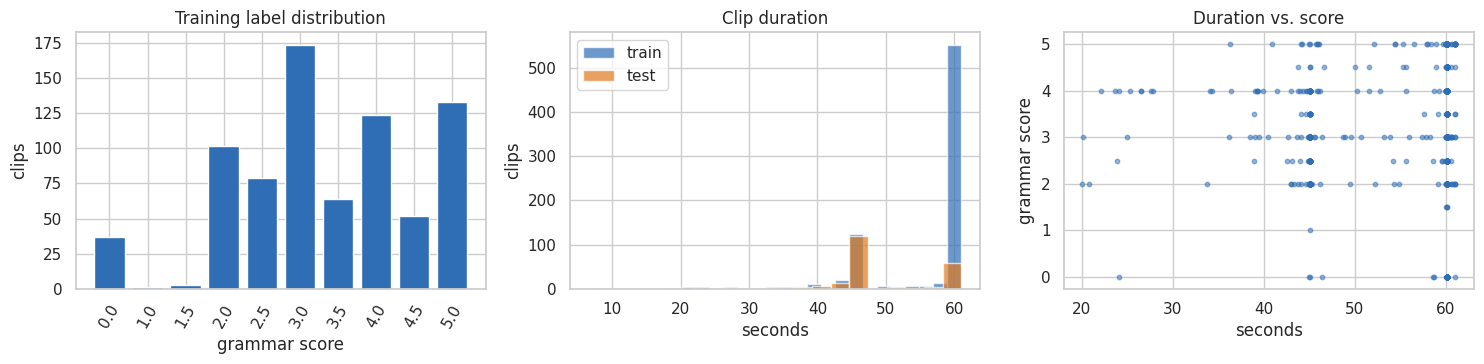

count    769.000
mean       3.313
std        1.239
min        0.000
25%        2.500
50%        3.000
75%        4.000
max        5.000

Baseline RMSE if we always predict the mean: 1.2382


In [5]:
import soundfile as sf
all_df["duration"] = [sf.info(str(audio_path(i))).duration for i in all_df.id]

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
vc = train[LABEL_COL].round(1).value_counts().sort_index()
ax[0].bar(vc.index.astype(str), vc.values, color=PALETTE["main"])
ax[0].set(title="Training label distribution", xlabel="grammar score", ylabel="clips")
ax[0].tick_params(axis="x", rotation=60)
for s, c in (("train", PALETTE["main"]), ("test", PALETTE["accent"])):
    ax[1].hist(all_df.loc[all_df.split == s, "duration"], bins=20, alpha=0.7, label=s, color=c)
ax[1].set(title="Clip duration", xlabel="seconds", ylabel="clips"); ax[1].legend()
tr = all_df[is_train]
ax[2].scatter(tr.duration, tr.label, s=10, alpha=0.5, color=PALETTE["main"])
ax[2].set(title="Duration vs. score", xlabel="seconds", ylabel="grammar score")
plt.tight_layout(); plt.show()

print(train[LABEL_COL].describe().round(3).to_string())
print(f"\nBaseline RMSE if we always predict the mean: {np.sqrt(np.mean((y - y.mean())**2)):.4f}")

## 2. Audio preprocessing
All clips are decoded to **16 kHz mono float32** (the rate Whisper and wav2vec2 expect), **leading/trailing silence is trimmed** (`top_db=30`; internal pauses are kept because they carry fluency information), and the waveform is **peak-normalised** so recording gain does not leak into the features.

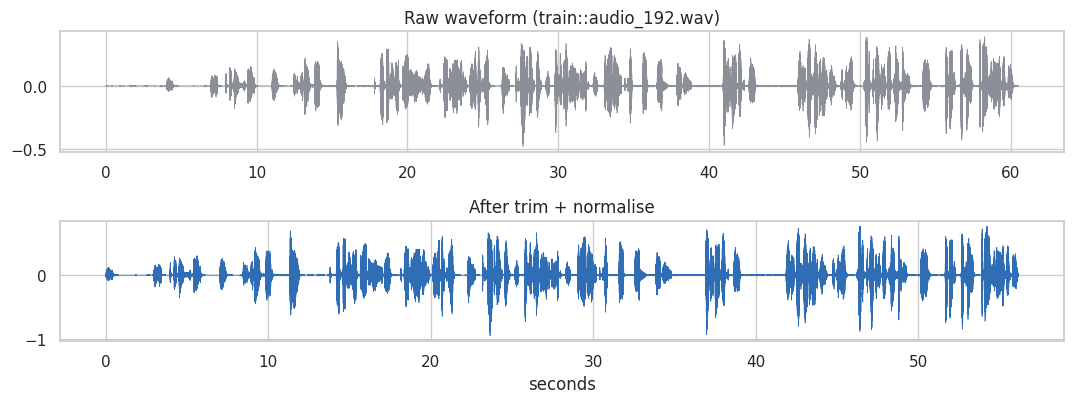

In [6]:
def load_audio(path, trim=True, top_db=30):
    """Decode -> 16 kHz mono -> trim edge silence -> peak-normalise."""
    import librosa
    wav, _ = librosa.load(str(path), sr=SR, mono=True)
    if trim and len(wav) > 0:
        wav, _ = librosa.effects.trim(wav, top_db=top_db)
    peak = np.max(np.abs(wav)) if len(wav) else 0.0
    if peak > 0:
        wav = wav / peak * 0.95
    return wav.astype(np.float32)

import librosa
demo_id = all_df.id.iloc[0]
raw, _ = librosa.load(str(audio_path(demo_id)), sr=SR, mono=True)
proc = load_audio(audio_path(demo_id))
fig, ax = plt.subplots(2, 1, figsize=(11, 4.2), sharex=False)
ax[0].plot(np.arange(len(raw)) / SR, raw, lw=0.5, color=PALETTE["neutral"]); ax[0].set_title(f"Raw waveform ({demo_id})")
ax[1].plot(np.arange(len(proc)) / SR, proc, lw=0.5, color=PALETTE["main"]); ax[1].set_title("After trim + normalise")
ax[1].set_xlabel("seconds"); plt.tight_layout(); plt.show()

## 3. Feature extraction
Each extraction block writes its result to `work/features/` and is skipped on re-runs if the cache exists.

### 3.1 Transcription (Whisper, word timestamps)
Whisper gives the transcript, per-word start/end times and per-word probabilities, plus segment-level `avg_logprob`, `no_speech_prob` and `compression_ratio`. Decoding is greedy (`temperature=0`) with `condition_on_previous_text=False` to limit hallucinated repetition.

*Caveat:* Whisper has a strong language-model prior and sometimes silently "corrects" ungrammatical speech, which makes the transcript look better than what was said. The word-probability and wav2vec2 features partly compensate for this, since they react to unusual or unclear delivery.

In [7]:
TRANSCRIPT_CACHE = FEAT / "transcripts.json"

def transcribe_all(ids):
    import torch, whisper
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = whisper.load_model(WHISPER_MODEL, device=device)
    out = {}
    for n, uid in enumerate(tqdm(ids, desc=f"Whisper-{WHISPER_MODEL} on {device}")):
        wav = load_audio(audio_path(uid))
        r = model.transcribe(wav, language="en", task="transcribe", word_timestamps=True,
                             temperature=0.0, condition_on_previous_text=False, fp16=(device == "cuda"))
        words, segs = [], []
        for s in r["segments"]:
            segs.append(dict(avg_logprob=s["avg_logprob"], no_speech_prob=s["no_speech_prob"],
                             compression_ratio=s["compression_ratio"], start=s["start"], end=s["end"]))
            for w in s.get("words", []):
                words.append(dict(word=w["word"].strip(), start=w["start"], end=w["end"], prob=w["probability"]))
        out[uid] = dict(text=r["text"].strip(), words=words, segments=segs, duration=len(wav) / SR)
        if (n + 1) % 100 == 0:                       # periodic checkpoint
            TRANSCRIPT_CACHE.write_text(json.dumps(out))
    return out

if TRANSCRIPT_CACHE.exists():
    transcripts = json.loads(TRANSCRIPT_CACHE.read_text())
    print("loaded cached transcripts:", len(transcripts))
else:
    transcripts = transcribe_all(list(all_df.id))
    TRANSCRIPT_CACHE.write_text(json.dumps(transcripts))
assert all(i in transcripts for i in all_df.id), "some clips have no transcript - delete the cache and re-run"

for uid in all_df.id[:2]:
    print(f"[{uid}] {transcripts[uid]['text'][:300]}...\n")

100%|███████████████████████████████████████| 461M/461M [00:06<00:00, 73.6MiB/s]


Whisper-small on cuda:   0%|          | 0/985 [00:00<?, ?it/s]

[train::audio_192.wav] The playground is very, very beautiful and fun. There are places like the merry-go-round swing. We usually enjoy the swing. It has to be like, it's more like a game of chess. was one-fifth a minute and the other five minutes we'll have to finish and then go around which was five minutes and most of ...

[train::audio_436.wav] The scene of a school playground, our playground looks like a very big playground having a more greenery trees in which we students like to garden more trees to have fresh air and all having fresh oxygen. This in the playground these trees gives a very greenery view which will very pleasant to our m...



### 3.2 Hand-crafted syntax and fluency features
Features are grouped by the rubric dimension they target:

| Group | Features | Rubric link |
|---|---|---|
| Sentence structure | sentence count / mean / max / std length, fraction of very short (<4 word) sentences, comma rate | "incomplete sentences", "sentence structure" |
| Syntactic complexity | subordinator / relative-pronoun rate, auxiliary-verb rate, word length, long-word ratio, type-token ratio | "complex grammar" |
| Disfluency & self-correction | filler rate, immediate word repeats, repeated-bigram ratio | "corrects themselves", memorised patterns |
| Fluency / timing | words per second, pause count / rate / mean / max, long pauses, pause ratio, articulation rate | proxy for control |
| ASR confidence | mean / min / std word probability, share of low-confidence words, segment log-prob, compression ratio | unusual or erroneous speech is decoded with low confidence |

In [8]:
FILLERS = {"um", "uh", "uhm", "umm", "er", "erm", "ah", "hmm", "mm", "eh"}
SUBORD  = {"because", "although", "though", "which", "that", "if", "when", "while", "whereas", "unless",
           "since", "whether", "who", "whom", "whose", "where", "after", "before", "until",
           "however", "therefore", "moreover"}
AUX     = {"is", "are", "was", "were", "be", "been", "being", "am", "do", "does", "did", "have", "has",
           "had", "will", "would", "can", "could", "should", "shall", "may", "might", "must"}

def norm_token(w):
    return re.sub(r"[^a-z']", "", w.lower())

def split_sentences(text):
    return [s.strip() for s in re.split(r"(?<=[.!?])\s+", text.strip()) if s.strip()]

def handcrafted_features(rec):
    words, text = rec["words"], rec["text"]
    toks = [t for t in (norm_token(w["word"]) for w in words) if t]
    n = max(len(toks), 1)
    f = {"n_words": len(toks), "words_per_sec": len(toks) / max(rec["duration"], 1e-6)}

    # ---- timing / pauses -------------------------------------------------------
    if len(words) > 1:
        starts = np.array([w["start"] for w in words]); ends = np.array([w["end"] for w in words])
        gaps = np.clip(starts[1:] - ends[:-1], 0, None)
        span = max(ends[-1] - starts[0], 1e-6)
        pauses = gaps[gaps > 0.25]
        f.update(pause_count=len(pauses), pause_rate=len(pauses) / span,
                 long_pause_count=int((gaps > 1.0).sum()),
                 mean_pause=float(pauses.mean()) if len(pauses) else 0.0, max_gap=float(gaps.max()),
                 pause_ratio=float(pauses.sum() / span),
                 articulation_rate=len(toks) / max(span - pauses.sum(), 1e-6))
    else:
        f.update(pause_count=0, pause_rate=0, long_pause_count=0, mean_pause=0, max_gap=0,
                 pause_ratio=0, articulation_rate=0)

    # ---- ASR confidence --------------------------------------------------------
    probs = np.array([w["prob"] for w in words]) if words else np.array([0.0])
    f.update(wprob_mean=probs.mean(), wprob_min=probs.min(), wprob_std=probs.std(),
             wprob_low_frac=(probs < 0.5).mean())
    segs = rec["segments"] or [dict(avg_logprob=0, no_speech_prob=0, compression_ratio=0)]
    f.update(seg_logprob_mean=np.mean([s["avg_logprob"] for s in segs]),
             seg_logprob_min=np.min([s["avg_logprob"] for s in segs]),
             seg_nospeech_mean=np.mean([s["no_speech_prob"] for s in segs]),
             seg_compress_mean=np.mean([s["compression_ratio"] for s in segs]))

    # ---- lexical / disfluency --------------------------------------------------
    bigrams = list(zip(toks, toks[1:]))
    f.update(filler_rate=sum(t in FILLERS for t in toks) / n,
             word_repeat_rate=sum(a == b for a, b in bigrams) / n,
             repeated_bigram_ratio=1 - len(set(bigrams)) / max(len(bigrams), 1),
             ttr=len(set(toks)) / n,
             avg_word_len=float(np.mean([len(t) for t in toks])) if toks else 0.0,
             long_word_ratio=sum(len(t) >= 7 for t in toks) / n,
             subord_rate=sum(t in SUBORD for t in toks) / n,
             aux_rate=sum(t in AUX for t in toks) / n,
             comma_rate=text.count(",") / n)

    # ---- sentence structure ----------------------------------------------------
    lens = [len(s.split()) for s in split_sentences(text)] or [0]
    f.update(n_sent=len(lens), sent_per_100w=len(lens) / n * 100, sent_len_mean=np.mean(lens),
             sent_len_std=np.std(lens), sent_len_max=np.max(lens),
             short_sent_frac=np.mean([l < 4 for l in lens]),
             ends_with_punct=float(text.strip()[-1:] in ".!?"))
    return f

HAND_CACHE = FEAT / "hand.csv"
if HAND_CACHE.exists():
    hand = pd.read_csv(HAND_CACHE, index_col=0)
else:
    hand = pd.DataFrame({uid: handcrafted_features(transcripts[uid]) for uid in tqdm(all_df.id)}).T
    hand.to_csv(HAND_CACHE)
hand.index = hand.index.astype(str)
hand = hand.loc[all_df.id].astype(float)
print("hand-crafted features:", hand.shape[1])
display(hand.describe().T.round(3).head(12))

  0%|          | 0/985 [00:00<?, ?it/s]

hand-crafted features: 33


,count,mean,std,min,25%,50%,75%,max
n_words,985.0,98.404,27.202,0.0,81.000,99.000,119.000,174.000
words_per_sec,985.0,1.921,0.466,0.0,1.657,1.953,2.238,3.351
pause_count,985.0,6.640,3.625,0.0,4.000,6.000,9.000,21.000
pause_rate,985.0,0.135,0.072,0.0,0.085,0.127,0.180,0.445
long_pause_count,985.0,1.772,1.640,0.0,1.000,1.000,3.000,13.000
mean_pause,985.0,0.993,0.792,0.0,0.640,0.825,1.133,16.455
max_gap,985.0,2.128,2.531,0.0,1.040,1.500,2.400,30.000
pause_ratio,985.0,0.127,0.084,0.0,0.070,0.115,0.165,0.731
articulation_rate,985.0,2.310,0.524,0.0,1.993,2.321,2.639,5.091
wprob_mean,985.0,0.859,0.097,0.0,0.829,0.881,0.916,0.979


### 3.3 Grammaticality from pretrained language models
* **CoLA acceptability** (`roberta-base-CoLA`): for each sentence, the probability that it is grammatically acceptable. We aggregate the mean, minimum, spread and the fraction of sentences judged unacceptable.
* **GPT-2 negative log-likelihood**: average per-token NLL of each sentence (and of the full transcript). Ungrammatical or broken sentences are less probable under a language model trained on fluent text.

Both are direct, rubric-aligned signals that go beyond surface counts.

In [9]:
GLM_CACHE = FEAT / "grammar_lm.csv"

def grammar_model_features(texts):
    import torch
    from transformers import (AutoTokenizer, AutoModelForSequenceClassification, AutoModelForCausalLM)
    device = "cuda" if torch.cuda.is_available() else "cpu"
    cola_tok = AutoTokenizer.from_pretrained(COLA_MODEL)
    cola = AutoModelForSequenceClassification.from_pretrained(COLA_MODEL).to(device).eval()
    gpt_tok = AutoTokenizer.from_pretrained("gpt2")
    gpt = AutoModelForCausalLM.from_pretrained("gpt2").to(device).eval()
    bos = torch.tensor([[gpt_tok.bos_token_id]], device=device)

    def nll(text):
        ids = gpt_tok(text, return_tensors="pt", truncation=True, max_length=900).input_ids.to(device)
        ids = torch.cat([bos, ids], dim=1)          # BOS so the first real token is scored too
        return gpt(ids, labels=ids).loss.item()

    rows = []
    for text in tqdm(texts, desc="CoLA + GPT-2"):
        sents = split_sentences(text) or [text or "."]
        with torch.no_grad():
            enc = cola_tok(sents, return_tensors="pt", padding=True, truncation=True, max_length=128).to(device)
            p = torch.softmax(cola(**enc).logits, -1)[:, 1].cpu().numpy()
            s_nll = np.array([nll(s) for s in sents])
            full_nll = nll(text or ".")
        rows.append(dict(cola_mean=p.mean(), cola_min=p.min(), cola_std=p.std(), cola_bad_frac=(p < 0.5).mean(),
                         gpt2_nll_mean=s_nll.mean(), gpt2_nll_max=s_nll.max(), gpt2_nll_std=s_nll.std(),
                         gpt2_nll_full=full_nll))
    return pd.DataFrame(rows)

glm = None
if USE_GRAMMAR_LM:
    if GLM_CACHE.exists():
        glm = pd.read_csv(GLM_CACHE, index_col=0)
    else:
        glm = grammar_model_features([transcripts[i]["text"] for i in all_df.id])
        glm.index = all_df.id.values
        glm.to_csv(GLM_CACHE)
    glm.index = glm.index.astype(str)
    glm = glm.loc[all_df.id].astype(float)
    print("grammar-LM features:", list(glm.columns))

config.json:   0%|          | 0.00/564 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

CoLA + GPT-2:   0%|          | 0/985 [00:00<?, ?it/s]

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


grammar-LM features: ['cola_mean', 'cola_min', 'cola_std', 'cola_bad_frac', 'gpt2_nll_mean', 'gpt2_nll_max', 'gpt2_nll_std', 'gpt2_nll_full']


### 3.4 Embeddings
* **wav2vec2** (`wav2vec2-base-960h`): time-pooled hidden states from layer 6 and 12 (mean) and layer 12 (std) -> 2304-d vector per clip. Mid layers carry phonetic / prosodic information, the top layer carries more lexical information.
* **MiniLM** sentence embedding of the Whisper transcript (384-d): a compact semantic / syntactic summary of the text.
* **Whisper encoder** (same size as the ASR model): mean / std of the encoder output over each 30 s window, averaged over the clip. The encoder was trained on 680k hours of speech and is a strong, general speech representation.
* **WavLM** (`wavlm-base-plus`): layer 4, 8 and 12 means plus layer 12 std; self-supervised features that are strong on prosody and speaking style.

Because there are only ~770 training clips, the embeddings are only used with strongly regularised linear / kernel models, never fine-tuned.

In [10]:
W2V_CACHE, TXT_CACHE = FEAT / "w2v.npy", FEAT / "txt.npy"

def wav2vec_embeddings(ids):
    import torch
    from transformers import Wav2Vec2FeatureExtractor, Wav2Vec2Model
    device = "cuda" if torch.cuda.is_available() else "cpu"
    fe = Wav2Vec2FeatureExtractor.from_pretrained(W2V_MODEL)
    model = Wav2Vec2Model.from_pretrained(W2V_MODEL).to(device).eval()
    out = []
    for uid in tqdm(ids, desc="wav2vec2"):
        wav = load_audio(audio_path(uid))
        inp = fe(wav, sampling_rate=SR, return_tensors="pt").input_values.to(device)
        with torch.no_grad():
            hs = model(inp, output_hidden_states=True).hidden_states
        out.append(torch.cat([hs[6][0].mean(0), hs[12][0].mean(0), hs[12][0].std(0)]).cpu().numpy())
    return np.stack(out)

def text_embeddings(texts):
    import torch
    from transformers import AutoTokenizer, AutoModel
    device = "cuda" if torch.cuda.is_available() else "cpu"
    tok = AutoTokenizer.from_pretrained(TXT_MODEL)
    model = AutoModel.from_pretrained(TXT_MODEL).to(device).eval()
    out = []
    for t in tqdm(texts, desc="MiniLM"):
        enc = tok(t, return_tensors="pt", truncation=True, max_length=512).to(device)
        with torch.no_grad():
            h = model(**enc).last_hidden_state[0]
        out.append(h.mean(0).cpu().numpy())
    return np.stack(out)

WENC_CACHE, WAVLM_CACHE = FEAT / "whisper_enc.npy", FEAT / "wavlm.npy"

def free_gpu():
    import gc; gc.collect()
    try:
        import torch; torch.cuda.empty_cache()
    except Exception:
        pass

def whisper_encoder_embeddings(ids):
    """Mean / std pooled Whisper-encoder output (30 s windows, only frames that cover real audio)."""
    import torch, whisper
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model = whisper.load_model(WHISPER_MODEL, device=device).eval()
    win, out = 30 * SR, []
    for uid in tqdm(ids, desc="Whisper encoder"):
        wav = load_audio(audio_path(uid))
        means, stds, weights = [], [], []
        for s0 in range(0, len(wav), win):
            chunk = wav[s0:s0 + win]
            if len(chunk) < SR and means:                      # ignore a sub-second tail
                continue
            mel = whisper.log_mel_spectrogram(whisper.pad_or_trim(torch.from_numpy(chunk)),
                                              n_mels=model.dims.n_mels).unsqueeze(0).to(device)
            with torch.no_grad():
                h = model.encoder(mel)[0]                      # (1500, d) for a 30 s window
            h = h[: max(2, int(np.ceil(len(chunk) / 320)))]    # 50 encoder frames per second
            means.append(h.mean(0).float().cpu().numpy()); stds.append(h.std(0).float().cpu().numpy())
            weights.append(len(h))
        if not means:
            out.append(np.zeros(2 * model.dims.n_audio_state)); continue
        w = np.array(weights, dtype=float) / np.sum(weights)
        out.append(np.concatenate([np.average(means, axis=0, weights=w), np.average(stds, axis=0, weights=w)]))
    del model; free_gpu()
    return np.stack(out)

def wavlm_embeddings(ids):
    import torch
    from transformers import AutoFeatureExtractor, WavLMModel
    device = "cuda" if torch.cuda.is_available() else "cpu"
    fe = AutoFeatureExtractor.from_pretrained(WAVLM_MODEL)
    model = WavLMModel.from_pretrained(WAVLM_MODEL).to(device).eval()
    out = []
    for uid in tqdm(ids, desc="WavLM"):
        wav = load_audio(audio_path(uid))
        inp = fe(wav, sampling_rate=SR, return_tensors="pt").input_values.to(device)
        with torch.no_grad():
            hs = model(inp, output_hidden_states=True).hidden_states
        out.append(torch.cat([hs[4][0].mean(0), hs[8][0].mean(0), hs[12][0].mean(0), hs[12][0].std(0)]).cpu().numpy())
    del model; free_gpu()
    return np.stack(out)

def cached(path, fn):
    """Load an embedding matrix from disk, or compute it once and save it."""
    if path.exists():
        return np.load(path)
    arr = fn(); np.save(path, arr); free_gpu()
    return arr

X_w2v = X_txt = X_wenc = X_wavlm = None
if USE_W2V:         X_w2v   = cached(W2V_CACHE,   lambda: wav2vec_embeddings(list(all_df.id)))
if USE_TXT_EMB:     X_txt   = cached(TXT_CACHE,   lambda: text_embeddings([transcripts[i]["text"] for i in all_df.id]))
if USE_WHISPER_ENC: X_wenc  = cached(WENC_CACHE,  lambda: whisper_encoder_embeddings(list(all_df.id)))
if USE_WAVLM:       X_wavlm = cached(WAVLM_CACHE, lambda: wavlm_embeddings(list(all_df.id)))
for nm, arr in (("wav2vec2", X_w2v), ("MiniLM text", X_txt), ("Whisper encoder", X_wenc), ("WavLM", X_wavlm)):
    if arr is not None:
        assert len(arr) == len(all_df), f"{nm}: {len(arr)} rows but {len(all_df)} clips - delete {FEAT} and re-run"
        print(f"{nm:16s}", arr.shape)

preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.60k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/210 [00:00<?, ?it/s]

...

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

WavLM:   0%|          | 0/985 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

wav2vec2         (985, 2304)
MiniLM text      (985, 384)
Whisper encoder  (985, 1536)
WavLM            (985, 3072)


## 4. Feature analysis

tabular feature matrix: (985, 41) | missing values: 0


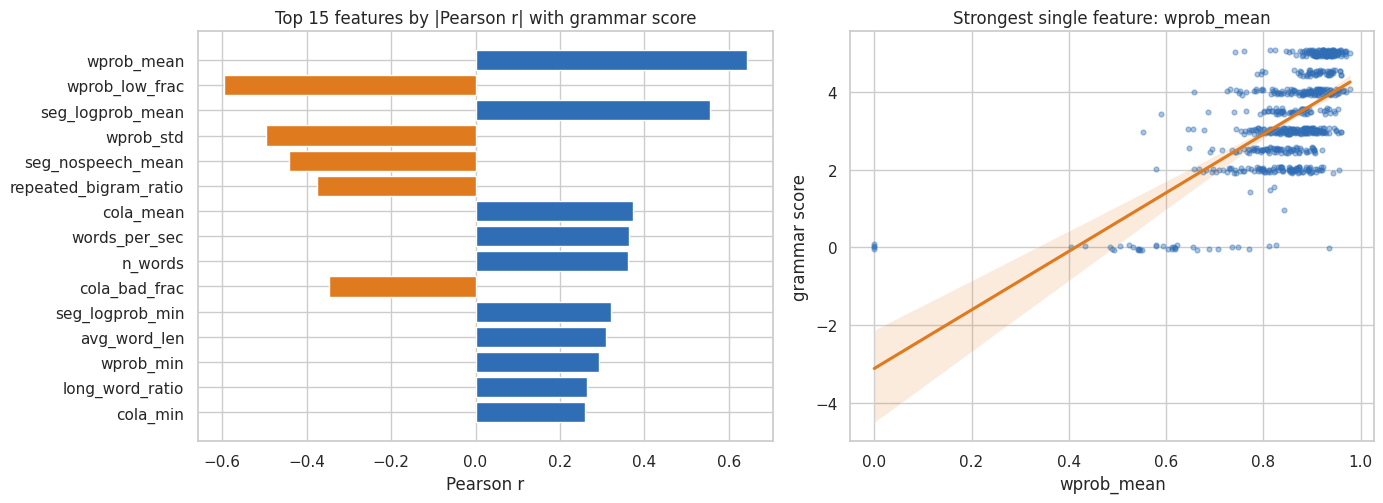

In [11]:
tab = pd.concat([hand] + ([glm] if glm is not None else []), axis=1).replace([np.inf, -np.inf], np.nan)
X_tab = tab.values
tab_cols = list(tab.columns)
print("tabular feature matrix:", X_tab.shape, "| missing values:", int(np.isnan(X_tab).sum()))

# Pearson correlation of every tabular feature with the grammar score (training rows only)
corr = tab[is_train].apply(lambda c: c.corr(pd.Series(y, index=c.index)) if c.std() > 0 else np.nan).dropna()
top = corr.reindex(corr.abs().sort_values(ascending=False).index)[:15][::-1]

fig, ax = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={"width_ratios": [1.1, 1]})
ax[0].barh(top.index, top.values, color=[PALETTE["main"] if v > 0 else PALETTE["accent"] for v in top.values])
ax[0].set(title="Top 15 features by |Pearson r| with grammar score", xlabel="Pearson r")
best = top.abs().idxmax()
sns.regplot(x=tab.loc[is_train, best].values, y=y, ax=ax[1], x_jitter=0, y_jitter=0.08,
            scatter_kws=dict(s=12, alpha=0.4, color=PALETTE["main"]), line_kws=dict(color=PALETTE["accent"]))
ax[1].set(title=f"Strongest single feature: {best}", xlabel=best, ylabel="grammar score")
plt.tight_layout(); plt.show()

## 5. Modelling
**Validation.** 5-fold CV, stratified on the rounded score so every fold sees the whole score range. All reported CV numbers use *out-of-fold* predictions (every clip is predicted by a model that never saw it).

**Base models** (one per feature view, so errors are diverse):

| Model | Input | Why |
|---|---|---|
| Ridge | hand-crafted + grammar-LM features | strong linear baseline, hard to overfit |
| SVR (RBF, C tuned in an inner CV) | same | captures non-linear interactions |
| LightGBM (shallow, strongly regularised) | same | handles skewed features / thresholds |
| Ridge | wav2vec2 embedding | acoustic / delivery view |
| Ridge | MiniLM transcript embedding | semantic / syntactic text view |
| Ridge | Whisper-encoder embedding | acoustic / prosody view from the ASR encoder |
| Ridge | WavLM embedding | self-supervised prosody / style features |
| RoBERTa-CoLA, fine-tuned (5-fold) | transcript text | starts from a grammaticality-aware model and learns the score directly |
| SVR on PCA(64) | all features concatenated | joint low-dimensional view |

**Stacking.** A non-negative linear regression on the out-of-fold predictions gives the final blend; non-negativity keeps the weights interpretable and stops the stacker from exploiting small fold noise. Predictions are clipped to [0, 5].

**On the compulsory training RMSE.** The headline *training RMSE* is the error of the final stacked model on the training clips, where each base prediction fed to the stacker comes from a model that did not see that clip (out-of-fold). It is therefore close to, and slightly below, the *cross-validated RMSE* (the stacker weights were fitted on the same data). The `Train RMSE` column of the results table additionally gives each base model's plain in-sample error after refitting on all training data; those numbers are lower because the models have seen those clips.

In [12]:
def rmse(a, b):  return float(np.sqrt(mean_squared_error(a, b)))
def metrics(a, b):
    return dict(RMSE=rmse(a, np.clip(b, 0, 5)), Pearson=pearsonr(a, b)[0], Spearman=spearmanr(a, b)[0])

strat = np.clip(np.round(y), 0, 5).astype(int)
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(np.zeros(len(y)), strat))

def prep():  return [SimpleImputer(strategy="median"), StandardScaler()]
def ridge(): return make_pipeline(*prep(), RidgeCV(alphas=np.logspace(-1, 5, 40)))
def svr():
    return GridSearchCV(make_pipeline(*prep(), SVR(kernel="rbf", epsilon=0.1)),
                        {"svr__C": [0.3, 1, 3, 10]}, cv=3, scoring="neg_root_mean_squared_error")
def lgbm():
    return make_pipeline(SimpleImputer(strategy="median"),
                         LGBMRegressor(n_estimators=300, learning_rate=0.03, num_leaves=8, min_child_samples=15,
                                       subsample=0.8, subsample_freq=1, colsample_bytree=0.7, reg_lambda=1.0,
                                       importance_type="gain", random_state=SEED, verbose=-1))
def svr_pca():
    return make_pipeline(*prep(), PCA(n_components=64, random_state=SEED), SVR(kernel="rbf", C=3, epsilon=0.1))

def run_cv(make_model, X):
    """Out-of-fold predictions, plus a full-data refit used for train / test predictions."""
    Xtr, Xte = X[is_train], X[~is_train]
    oof = np.zeros(len(y))
    for tr_idx, va_idx in folds:
        m = make_model().fit(Xtr[tr_idx], y[tr_idx])
        oof[va_idx] = m.predict(Xtr[va_idx])
    full = make_model().fit(Xtr, y)
    return oof, full.predict(Xtr), full.predict(Xte), full

views = {"Ridge (hand-crafted + grammar LM)": (ridge, X_tab),
         "SVR (hand-crafted + grammar LM)":   (svr,   X_tab),
         "LightGBM (hand-crafted + grammar LM)": (lgbm, X_tab)}
if X_w2v   is not None: views["Ridge (wav2vec2)"]        = (ridge, X_w2v)
if X_wenc  is not None: views["Ridge (Whisper encoder)"] = (ridge, X_wenc)
if X_wavlm is not None: views["Ridge (WavLM)"]           = (ridge, X_wavlm)
if X_txt   is not None: views["Ridge (MiniLM text)"]     = (ridge, X_txt)
parts = [X_tab] + [a for a in (X_w2v, X_wenc, X_wavlm, X_txt) if a is not None]
views["SVR on PCA (all features)"] = (svr_pca, np.hstack(parts))

res, oof_all, train_all, test_all, fitted = [], {}, {}, {}, {}
for name, (mk, X) in views.items():
    oof, trn, tst, full = run_cv(mk, X)
    oof_all[name], train_all[name], test_all[name], fitted[name] = oof, trn, tst, full
    res.append({"model": name, **{f"CV {k}": v for k, v in metrics(y, oof).items()},
                "Train RMSE": rmse(y, np.clip(trn, 0, 5))})
    print(f"{name:42s} CV RMSE {res[-1]['CV RMSE']:.4f}   CV Pearson {res[-1]['CV Pearson']:.4f}")

Ridge (hand-crafted + grammar LM)          CV RMSE 0.7249   CV Pearson 0.8086
SVR (hand-crafted + grammar LM)            CV RMSE 0.8325   CV Pearson 0.7404
LightGBM (hand-crafted + grammar LM)       CV RMSE 0.7515   CV Pearson 0.7938
Ridge (wav2vec2)                           CV RMSE 0.6287   CV Pearson 0.8602
Ridge (Whisper encoder)                    CV RMSE 0.5707   CV Pearson 0.8856
Ridge (WavLM)                              CV RMSE 0.5539   CV Pearson 0.8932
Ridge (MiniLM text)                        CV RMSE 0.9935   CV Pearson 0.5946
SVR on PCA (all features)                  CV RMSE 0.5457   CV Pearson 0.8978


### 5.0 Fine-tuned transcript regressor
`roberta-base-CoLA` already knows what an acceptable English sentence looks like. We replace its classification head by a regression head and fine-tune the whole network on the transcripts (5 folds, 4 epochs, small learning rate, targets standardised). Out-of-fold predictions are produced with the same folds as the other models, and the test prediction is the average of the five fold models, so there is no leakage. This step needs a GPU; the result is cached.

*Note:* for this model there is no single full-data model, so the `Train RMSE` shown for it in the results table is its out-of-fold RMSE.

In [13]:
FT_OOF, FT_TEST = FEAT / "ft_text_oof.npy", FEAT / "ft_text_test.npy"
FT_NAME = "RoBERTa-CoLA fine-tuned (transcript)"

def finetune_text_cv(texts_tr, y_tr, texts_te, folds, epochs=4, lr=2e-5, bs=8, max_len=384):
    import torch
    from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
    device = "cuda" if torch.cuda.is_available() else "cpu"
    tok = AutoTokenizer.from_pretrained(COLA_MODEL)
    mu, sd = y_tr.mean(), y_tr.std()
    yz = (y_tr - mu) / sd
    enc = lambda t: tok(list(t), truncation=True, max_length=max_len, padding=True, return_tensors="pt")

    def predict(model, texts):
        model.eval(); out = []
        with torch.no_grad():
            for i in range(0, len(texts), 32):
                b = enc(texts[i:i + 32]).to(device)
                with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
                    out.append(model(**b).logits.squeeze(-1).float().cpu().numpy())
        return np.concatenate(out) * sd + mu

    oof, te_pred = np.zeros(len(y_tr)), np.zeros(len(texts_te))
    for k, (tr_idx, va_idx) in enumerate(folds):
        torch.manual_seed(SEED + k)
        model = AutoModelForSequenceClassification.from_pretrained(
            COLA_MODEL, num_labels=1, ignore_mismatched_sizes=True).to(device)
        opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=0.01)
        steps = epochs * int(np.ceil(len(tr_idx) / bs))
        sched = get_linear_schedule_with_warmup(opt, int(0.1 * steps), steps)
        scaler = torch.cuda.amp.GradScaler(enabled=(device == "cuda"))
        for ep in range(epochs):
            model.train()
            perm = np.random.RandomState(SEED + 100 * k + ep).permutation(tr_idx)
            for i in range(0, len(perm), bs):
                idx = perm[i:i + bs]
                b = enc([texts_tr[j] for j in idx]).to(device)
                target = torch.tensor(yz[idx], dtype=torch.float32, device=device)
                with torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(device == "cuda")):
                    pred = model(**b).logits.squeeze(-1)
                loss = torch.nn.functional.mse_loss(pred.float(), target)
                opt.zero_grad(); scaler.scale(loss).backward(); scaler.unscale_(opt)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(opt); scaler.update(); sched.step()
        oof[va_idx] = predict(model, [texts_tr[j] for j in va_idx])
        te_pred += predict(model, texts_te) / len(folds)
        print(f"fold {k}: RMSE {rmse(y_tr[va_idx], oof[va_idx]):.4f}")
        del model, opt; free_gpu()
    return oof, te_pred

ft_oof = ft_test = None
if USE_FT_TEXT:
    if FT_OOF.exists() and FT_TEST.exists():
        ft_oof, ft_test = np.load(FT_OOF), np.load(FT_TEST)
    elif HAS_GPU:
        tx_tr = [transcripts[i]["text"] for i in all_df.id[is_train]]
        tx_te = [transcripts[i]["text"] for i in all_df.id[~is_train]]
        ft_oof, ft_test = finetune_text_cv(tx_tr, y, tx_te, folds)
        np.save(FT_OOF, ft_oof); np.save(FT_TEST, ft_test)
    else:
        print("No GPU: skipping the fine-tuned transcript model.")

if ft_oof is not None:
    assert len(ft_oof) == len(y) and len(ft_test) == (~is_train).sum()
    oof_all[FT_NAME], train_all[FT_NAME], test_all[FT_NAME] = ft_oof, ft_oof, ft_test
    res.append({"model": FT_NAME, **{f"CV {k}": v for k, v in metrics(y, ft_oof).items()},
                "Train RMSE": rmse(y, np.clip(ft_oof, 0, 5))})
    print(f"{FT_NAME:42s} CV RMSE {res[-1]['CV RMSE']:.4f}   CV Pearson {res[-1]['CV Pearson']:.4f}")

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: textattack/roberta-base-CoLA
Key                         | Status     |                                                                                       
----------------------------+------------+---------------------------------------------------------------------------------------
roberta.pooler.dense.weight | UNEXPECTED |                                                                                       
roberta.pooler.dense.bias   | UNEXPECTED |                                                                                       
classifier.out_proj.bias    | MISMATCH   | Reinit due to size mismatch - ckpt: torch.Size([2]) vs model:torch.Size([1])          
classifier.out_proj.weight  | MISMATCH   | Reinit due to size mismatch - ckpt: torch.Size([2, 768]) vs model:torch.Size([1, 768])

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MI

fold 0: RMSE 0.9936


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: textattack/roberta-base-CoLA
Key                         | Status     |                                                                                       
----------------------------+------------+---------------------------------------------------------------------------------------
roberta.pooler.dense.weight | UNEXPECTED |                                                                                       
roberta.pooler.dense.bias   | UNEXPECTED |                                                                                       
classifier.out_proj.bias    | MISMATCH   | Reinit due to size mismatch - ckpt: torch.Size([2]) vs model:torch.Size([1])          
classifier.out_proj.weight  | MISMATCH   | Reinit due to size mismatch - ckpt: torch.Size([2, 768]) vs model:torch.Size([1, 768])

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MI

...

[transformers] RobertaForSequenceClassification LOAD REPORT from: textattack/roberta-base-CoLA
Key                         | Status     |                                                                                       
----------------------------+------------+---------------------------------------------------------------------------------------
roberta.pooler.dense.weight | UNEXPECTED |                                                                                       
roberta.pooler.dense.bias   | UNEXPECTED |                                                                                       
classifier.out_proj.bias    | MISMATCH   | Reinit due to size mismatch - ckpt: torch.Size([2]) vs model:torch.Size([1])          
classifier.out_proj.weight  | MISMATCH   | Reinit due to size mismatch - ckpt: torch.Size([2, 768]) vs model:torch.Size([1, 768])

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MI

fold 3: RMSE 0.8827


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: textattack/roberta-base-CoLA
Key                         | Status     |                                                                                       
----------------------------+------------+---------------------------------------------------------------------------------------
roberta.pooler.dense.weight | UNEXPECTED |                                                                                       
roberta.pooler.dense.bias   | UNEXPECTED |                                                                                       
classifier.out_proj.bias    | MISMATCH   | Reinit due to size mismatch - ckpt: torch.Size([2]) vs model:torch.Size([1])          
classifier.out_proj.weight  | MISMATCH   | Reinit due to size mismatch - ckpt: torch.Size([2, 768]) vs model:torch.Size([1, 768])

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MI

fold 4: RMSE 0.8978
RoBERTa-CoLA fine-tuned (transcript)       CV RMSE 0.9155   CV Pearson 0.7214


### 5.1 Stacking

In [14]:
names = list(oof_all)
O  = np.column_stack([oof_all[n] for n in names])      # out-of-fold matrix  (n_train x n_models)
Tr = np.column_stack([train_all[n] for n in names])    # full-fit predictions on train
Te = np.column_stack([test_all[n] for n in names])     # full-fit predictions on test

stacker = LinearRegression(positive=True)
# honest CV estimate of the stacker: second-level CV over the out-of-fold matrix
stack_oof = cross_val_predict(stacker, O, y, cv=KFold(5, shuffle=True, random_state=SEED + 1))
stacker.fit(O, y)
# Training RMSE of the stacked model: the stacker is evaluated on the training clips, with out-of-fold base predictions as
# inputs (the same kind of input it was fitted on). Feeding it the base models' in-sample predictions would be wrong: those
# are overfitted and live on a different scale than the out-of-fold predictions the stacker weights were learned from.
stack_train = np.clip(stacker.predict(O), 0, 5)
stack_test  = np.clip(stacker.predict(Te), 0, 5)

res.append({"model": "STACK (final)", **{f"CV {k}": v for k, v in metrics(y, stack_oof).items()},
            "Train RMSE": rmse(y, stack_train)})
mean_pred = np.full_like(y, y.mean())
res.append({"model": "Baseline: predict mean", "CV RMSE": rmse(y, mean_pred), "CV Pearson": np.nan,
            "CV Spearman": np.nan, "Train RMSE": rmse(y, mean_pred)})
results = pd.DataFrame(res).set_index("model").round(4)
display(results)

weights = pd.Series(stacker.coef_, index=names)
print("stacker weights:\n", weights.round(3).to_string(), f"\nintercept: {stacker.intercept_:.3f}")

,CV RMSE,CV Pearson,CV Spearman,Train RMSE
model,,,,
Ridge (hand-crafted + grammar LM),0.7249,0.8086,0.7789,0.6828
SVR (hand-crafted + grammar LM),0.8325,0.7404,0.7147,0.5873
LightGBM (hand-crafted + grammar LM),0.7515,0.7938,0.7502,0.4236
Ridge (wav2vec2),0.6287,0.8602,0.7951,0.4437
Ridge (Whisper encoder),0.5707,0.8856,0.8460,0.3818
Ridge (WavLM),0.5539,0.8932,0.8500,0.3288
Ridge (MiniLM text),0.9935,0.5946,0.6075,0.7842
SVR on PCA (all features),0.5457,0.8978,0.8547,0.2543
RoBERTa-CoLA fine-tuned (transcript),0.9155,0.7214,0.7591,0.9155


stacker weights:
 Ridge (hand-crafted + grammar LM)       0.097
SVR (hand-crafted + grammar LM)         0.000
LightGBM (hand-crafted + grammar LM)    0.000
Ridge (wav2vec2)                        0.000
Ridge (Whisper encoder)                 0.094
Ridge (WavLM)                           0.378
Ridge (MiniLM text)                     0.072
SVR on PCA (all features)               0.337
RoBERTa-CoLA fine-tuned (transcript)    0.162 
intercept: -0.542


### 5.2 Results and diagnostics


### Final model - headline numbers
| | RMSE | Pearson |
|---|---|---|
| **Training RMSE (compulsory)** - final stacked model evaluated on the training clips | **0.4926** | 0.9177 |
| 5-fold cross-validated (out-of-fold, unseen data) | 0.4976 | 0.9145 |
| Baseline: always predict the training mean | 1.2382 | - |


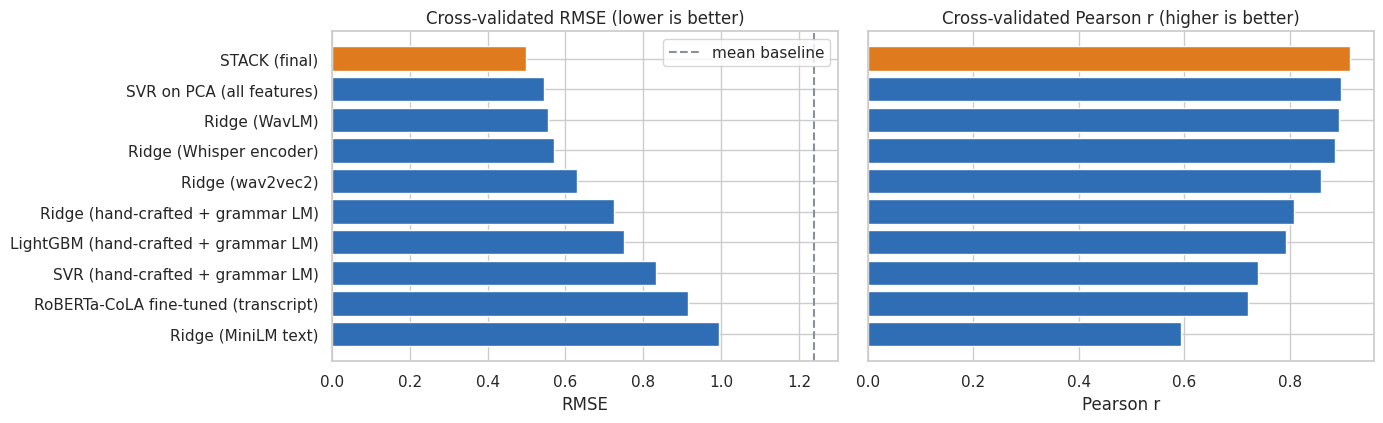

In [15]:
FINAL_TRAIN_RMSE = rmse(y, stack_train)
FINAL_CV = metrics(y, stack_oof)
FINAL_TRAIN_PEARSON = pearsonr(y, stack_train)[0]

display(Markdown(f"""
### Final model - headline numbers
| | RMSE | Pearson |
|---|---|---|
| **Training RMSE (compulsory)** - final stacked model evaluated on the training clips | **{FINAL_TRAIN_RMSE:.4f}** | {FINAL_TRAIN_PEARSON:.4f} |
| 5-fold cross-validated (out-of-fold, unseen data) | {FINAL_CV['RMSE']:.4f} | {FINAL_CV['Pearson']:.4f} |
| Baseline: always predict the training mean | {rmse(y, mean_pred):.4f} | - |
"""))

order = results.drop(["Baseline: predict mean"]).sort_values("CV RMSE", ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4), sharey=True)
colors = [PALETTE["accent"] if m.startswith("STACK") else PALETTE["main"] for m in order.index]
ax[0].barh(order.index, order["CV RMSE"], color=colors)
ax[0].axvline(rmse(y, mean_pred), color=PALETTE["neutral"], ls="--", label="mean baseline"); ax[0].legend()
ax[0].set(title="Cross-validated RMSE (lower is better)", xlabel="RMSE")
ax[1].barh(order.index, order["CV Pearson"], color=colors)
ax[1].set(title="Cross-validated Pearson r (higher is better)", xlabel="Pearson r")
plt.tight_layout(); plt.show()

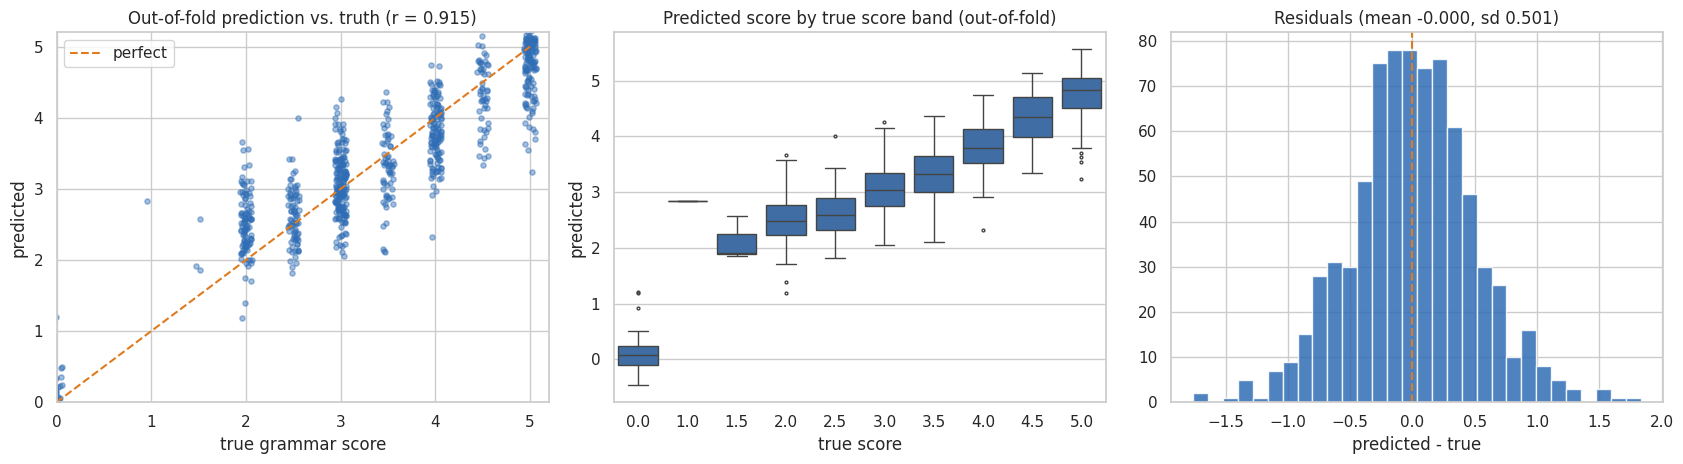

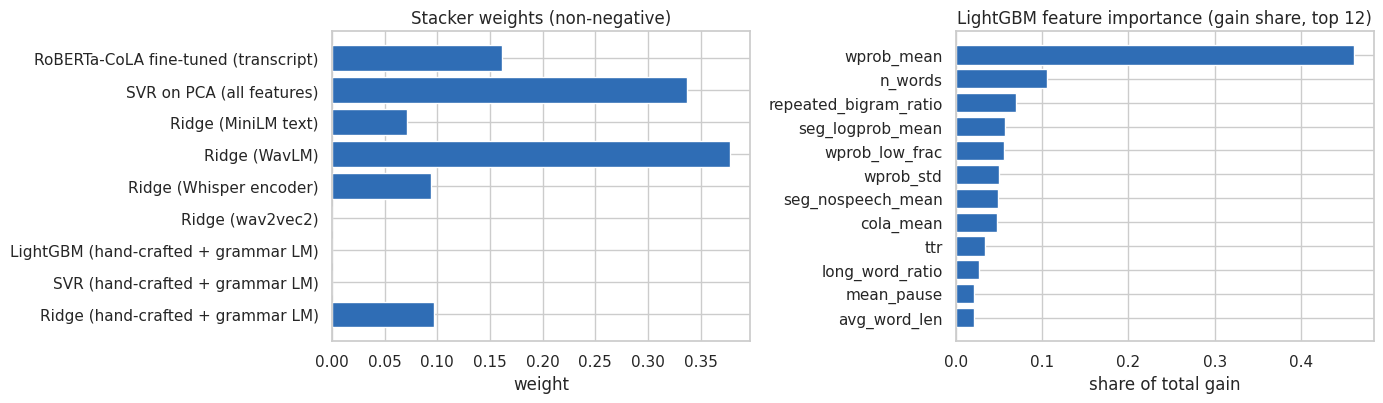

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))

# predicted vs. true (out-of-fold)
jit = np.random.RandomState(0).uniform(-0.06, 0.06, len(y))
ax[0].scatter(y + jit, stack_oof, s=14, alpha=0.45, color=PALETTE["main"])
ax[0].plot([0, 5], [0, 5], color=PALETTE["accent"], ls="--", label="perfect")
ax[0].set(title=f"Out-of-fold prediction vs. truth (r = {FINAL_CV['Pearson']:.3f})",
          xlabel="true grammar score", ylabel="predicted", xlim=(0, 5.2), ylim=(0, 5.2)); ax[0].legend()

# distribution of predictions per true score
bins = pd.Series(np.round(y * 2) / 2, name="true score")
sns.boxplot(x=bins, y=pd.Series(stack_oof, name="predicted"), ax=ax[1], color=PALETTE["main"], fliersize=2)
ax[1].set_title("Predicted score by true score band (out-of-fold)")

# residuals
resid = stack_oof - y
ax[2].hist(resid, bins=30, color=PALETTE["main"], alpha=0.85)
ax[2].axvline(0, color=PALETTE["accent"], ls="--")
ax[2].set(title=f"Residuals (mean {resid.mean():+.3f}, sd {resid.std():.3f})", xlabel="predicted - true")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].barh(weights.index, weights.values, color=PALETTE["main"])
ax[0].set(title="Stacker weights (non-negative)", xlabel="weight")
lgb = fitted["LightGBM (hand-crafted + grammar LM)"][-1]
imp = pd.Series(lgb.feature_importances_, index=tab_cols).sort_values().tail(12)
ax[1].barh(imp.index, imp.values / imp.values.sum(), color=PALETTE["main"])
ax[1].set(title="LightGBM feature importance (gain share, top 12)", xlabel="share of total gain")
plt.tight_layout(); plt.show()

### 5.3 Error analysis

In [17]:
err = pd.DataFrame({"id": all_df.id[is_train].values, "true": y, "pred": stack_oof, "abs_err": np.abs(resid),
                    "n_words": hand.loc[is_train, "n_words"].values,
                    "wprob_mean": hand.loc[is_train, "wprob_mean"].values})
print("Mean absolute error by true score band:")
print(err.assign(band=np.round(err.true)).groupby("band").abs_err.agg(["count", "mean"]).round(3).to_string())
print("\nLargest errors:")
display(err.sort_values("abs_err", ascending=False).head(8).round(3))

Mean absolute error by true score band:
      count   mean
band              
0.0      37  0.269
1.0       1  1.833
2.0     184  0.455
3.0     174  0.345
4.0     240  0.394
5.0     133  0.356

Largest errors:


,id,true,pred,abs_err,n_words,wprob_mean
423,train::audio_108.wav,1.0,2.833,1.833,137.0,0.842
226,train::audio_357.wav,5.0,3.238,1.762,79.0,0.889
465,train::audio_238.wav,4.0,2.324,1.676,27.0,0.785
636,train::audio_177.wav,2.0,3.663,1.663,111.0,0.858
162,train::audio_128.wav,2.0,3.567,1.567,110.0,0.792
534,train::audio_55.wav,2.0,3.545,1.545,90.0,0.870
38,train::audio_170.wav,2.5,4.001,1.501,152.0,0.903
606,train::audio_159.wav,5.0,3.541,1.459,96.0,0.760


## 6. Test predictions and submission

saved submission.csv (216, 2) using the ids in test.csv
note: only 12% of the ids in sample_submission.csv match test.csv


,filename,label
0,audio_128.wav,3.135608
1,audio_156.wav,4.220897
2,audio_19.wav,4.622117
3,audio_108.wav,1.833475
4,audio_206.wav,2.176889


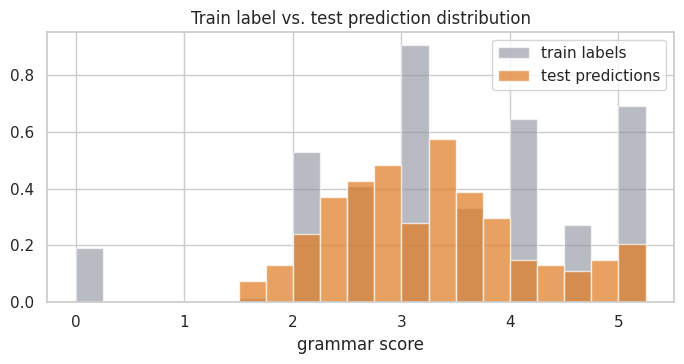

In [18]:
# predictions for the clips listed in test.csv (stack_test is in test.csv order)
submission = pd.DataFrame({"filename": test[ID_COL].astype(str).values, "label": np.clip(stack_test, 0, 5)})
assert len(submission) == len(test) and submission["label"].notna().all()
submission.to_csv("submission.csv", index=False)
match = sample_sub.iloc[:, 0].astype(str).isin(submission["filename"]).mean()
print(f"saved submission.csv {submission.shape} using the ids in test.csv")
if match < 1:
    print(f"note: only {match:.0%} of the ids in sample_submission.csv match test.csv")
display(submission.head())

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.hist(y, bins=np.arange(0, 5.5, 0.25), alpha=0.6, density=True, label="train labels", color=PALETTE["neutral"])
ax.hist(stack_test, bins=np.arange(0, 5.5, 0.25), alpha=0.7, density=True, label="test predictions", color=PALETTE["accent"])
ax.set(title="Train label vs. test prediction distribution", xlabel="grammar score"); ax.legend()
plt.tight_layout(); plt.show()

json.dump({"train_rmse": FINAL_TRAIN_RMSE, "train_pearson": FINAL_TRAIN_PEARSON,
           "cv_rmse": FINAL_CV["RMSE"], "cv_pearson": FINAL_CV["Pearson"],
           "cv_spearman": FINAL_CV["Spearman"]}, open(WORK / "metrics.json", "w"), indent=2)

## 7. Report

In [19]:
display(Markdown(f"""
### Summary of results
* **Training RMSE (final stacked model): {FINAL_TRAIN_RMSE:.4f}** (Pearson {FINAL_TRAIN_PEARSON:.4f}).
* **5-fold cross-validated RMSE: {FINAL_CV['RMSE']:.4f}**, Pearson {FINAL_CV['Pearson']:.4f}, Spearman {FINAL_CV['Spearman']:.4f}
  versus a mean-prediction baseline RMSE of {rmse(y, mean_pred):.4f}.
* The cross-validated number is the one to expect on unseen clips. The in-sample `Train RMSE` of the individual models in the results table is lower than their CV RMSE, which shows how much each model fits the training clips beyond what generalises.

### Preprocessing
16 kHz mono decoding, edge-silence trimming (internal pauses preserved), peak normalisation. Test labels in `test.csv` are random and were never used.

### Pipeline architecture
Whisper transcript with word timing -> {{CoLA + GPT-2 grammaticality, hand-crafted syntax / fluency features, MiniLM text embedding, fine-tuned RoBERTa-CoLA}} and wav2vec2 / Whisper-encoder / WavLM acoustic embeddings -> base regressors on different feature views (plus a RoBERTa-CoLA regressor fine-tuned on the transcripts) -> non-negative linear stacker -> clip to [0, 5].

### Why this design
* The rubric describes sentence structure, completeness, grammatical control and self-correction. The CoLA / GPT-2 / sentence-structure features measure those directly on the transcript; pause, repetition and confidence features capture delivery.
* With under 800 training clips, fine-tuning a large speech model is likely to overfit, so frozen pretrained models are used as feature extractors with small regularised regressors.
* Stacking diverse views reduces variance and was evaluated with out-of-fold predictions, so the reported CV score is not inflated by tuning on the evaluation data.

### Limitations and next steps
* **ASR normalisation:** Whisper may repair grammatical errors, hiding them from the text features. Adding a literal CTC transcript (e.g. wav2vec2-CTC output) and comparing it with the Whisper transcript is a promising extra signal.
* **Label noise:** MOS-style labels are subjective; the ceiling for RMSE is limited by annotator disagreement.
* **Possible improvements:** a larger Whisper model, fine-tuning a speech encoder with LoRA, ordinal-aware losses, repeated-CV seed averaging, and a dependency-parse based error-rate feature (e.g. LanguageTool).
"""))


### Summary of results
* **Training RMSE (final stacked model): 0.4926** (Pearson 0.9177).
* **5-fold cross-validated RMSE: 0.4976**, Pearson 0.9145, Spearman 0.8830
  versus a mean-prediction baseline RMSE of 1.2382.
* The cross-validated number is the one to expect on unseen clips. The in-sample `Train RMSE` of the individual models in the results table is lower than their CV RMSE, which shows how much each model fits the training clips beyond what generalises.

### Preprocessing
16 kHz mono decoding, edge-silence trimming (internal pauses preserved), peak normalisation. Test labels in `test.csv` are random and were never used.

### Pipeline architecture
Whisper transcript with word timing -> {CoLA + GPT-2 grammaticality, hand-crafted syntax / fluency features, MiniLM text embedding, fine-tuned RoBERTa-CoLA} and wav2vec2 / Whisper-encoder / WavLM acoustic embeddings -> base regressors on different feature views (plus a RoBERTa-CoLA regressor fine-tuned on the transcripts) -> non-negative linear stacker -> clip to [0, 5].

### Why this design
* The rubric describes sentence structure, completeness, grammatical control and self-correction. The CoLA / GPT-2 / sentence-structure features measure those directly on the transcript; pause, repetition and confidence features capture delivery.
* With under 800 training clips, fine-tuning a large speech model is likely to overfit, so frozen pretrained models are used as feature extractors with small regularised regressors.
* Stacking diverse views reduces variance and was evaluated with out-of-fold predictions, so the reported CV score is not inflated by tuning on the evaluation data.

### Limitations and next steps
* **ASR normalisation:** Whisper may repair grammatical errors, hiding them from the text features. Adding a literal CTC transcript (e.g. wav2vec2-CTC output) and comparing it with the Whisper transcript is a promising extra signal.
* **Label noise:** MOS-style labels are subjective; the ceiling for RMSE is limited by annotator disagreement.
* **Possible improvements:** a larger Whisper model, fine-tuning a speech encoder with LoRA, ordinal-aware losses, repeated-CV seed averaging, and a dependency-parse based error-rate feature (e.g. LanguageTool).
